# Workshop 1 - Source Profiling (Team 2, Flood Monitoring and Risk, Texas)

This notebook profiles the four sources from the **raw samples** saved by
`scripts/fetch_samples.py` and `scripts/poll_incremental.py` (it does not download anything).

| Role | Source | Sample location |
|---|---|---|
| Historical 1 | NOAA Storm Events (Flood, Flash Flood, Heavy Rain) | `workshop_1/samples/storm_events/` |
| Historical 2 | GHCN-Daily PRCP via NCEI Access Data Service | `workshop_1/samples/ghcnd/` |
| Incremental 1 | NWS station observations | `workshop_1/samples/polls/poll_*/nws_observations/` |
| Incremental 2 | NWS alerts (active + recent) | `workshop_1/samples/polls/poll_*/nws_alerts/` |

Run top to bottom (*Kernel > Restart & Run All*).

In [1]:
import json, math, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
S = ROOT / "workshop_1" / "samples"
TX_BBOX = dict(min_lat=25.8, max_lat=36.5, min_lon=-106.65, max_lon=-93.5)
polls = sorted(p for p in (S / "polls").glob("poll_*") if p.is_dir())
assert polls, "No polls found: run scripts/fetch_samples.py first"
LATEST = polls[-1]
print("Samples:", S)
print("Polls found:", [p.name for p in polls], "-> using", LATEST.name)

def read_json(p):
    return json.loads(Path(p).read_text(encoding="utf-8"))

def in_tx(lat, lon):
    return lat.between(TX_BBOX["min_lat"], TX_BBOX["max_lat"]) & lon.between(TX_BBOX["min_lon"], TX_BBOX["max_lon"])

def profile(df, name, id_cols):
    """Generic profile: size, nulls per field, duplicated identifiers."""
    nulls = (df.isna() | df.astype(str).eq("")).mean().mul(100).round(1)
    dup = df.duplicated(subset=id_cols, keep=False).sum()
    print(f"{name}: {len(df)} records, {df.shape[1]} fields, duplicated {id_cols}: {dup}")
    return nulls.rename("null_%").to_frame().T

def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp, dl = p2 - p1, np.radians(lon2 - lon1)
    a = np.sin(dp/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 2*r*np.arcsin(np.sqrt(a))

findings = []   # data-quality findings collected along the way
def finding(source, problem, count, total, example, impact):
    findings.append(dict(source=source, problem=problem, affected=f"{count}/{total}",
                         example=example, impact_on_design=impact))

Samples: /home/claude/flood-monitoring-team2/workshop_1/samples
Polls found: ['poll_20261106T022015Z', 'poll_20261106T032630Z'] -> using poll_20261106T032630Z


## 1. Historical 1 - NOAA Storm Events (Texas, flood-related event types)

In [2]:
se_file = sorted((S / "storm_events").glob("texas_floods_*.csv"))[-1]
se = pd.read_csv(se_file, dtype=str)
print(se_file.name)
print((S / "storm_events" / se_file.name.replace(".csv", "_summary.txt")).read_text())
se[["EVENT_ID","EPISODE_ID","EVENT_TYPE","BEGIN_DATE_TIME","CZ_TIMEZONE","CZ_TYPE","CZ_NAME",
    "BEGIN_LAT","BEGIN_LON","DAMAGE_PROPERTY","FLOOD_CAUSE","SOURCE"]].head()

texas_floods_2025.csv
source file: StormEvents_details-ftp_v1.0_d2025_c20260819.csv.gz
all rows in file: 72360
Texas Flood/Flash Flood/Heavy Rain rows: 724
by type:
EVENT_TYPE
Flash Flood    624
Flood           50
Heavy Rain      50



,EVENT_ID,EPISODE_ID,EVENT_TYPE,BEGIN_DATE_TIME,CZ_TIMEZONE,CZ_TYPE,CZ_NAME,BEGIN_LAT,BEGIN_LON,DAMAGE_PROPERTY,FLOOD_CAUSE,SOURCE
0,1256799,202180,Flood,21-APR-25 10:30:00,CST-6,C,WILLACY,26.5513,-97.424,0.00K,Heavy Rain,COOP Observer
1,1286074,205687,Flash Flood,08-JUL-25 18:55:00,CST-6,C,DALLAS,32.82,-96.92,0.00K,Heavy Rain,Trained Spotter
2,1233050,199400,Flash Flood,29-JAN-25 23:15:00,CST-6,C,DALLAS,32.81,-97.03,10.00K,Heavy Rain,Social Media
3,1233052,199400,Flash Flood,29-JAN-25 23:58:00,CST-6,C,ELLIS,32.49,-96.81,2.00K,Heavy Rain,Emergency Manager
4,1233204,199400,Flash Flood,30-JAN-25 00:00:00,CST-6,C,DALLAS,32.82,-96.8,0.00K,Heavy Rain,Broadcast Media


In [3]:
key_cols = ["EVENT_ID","EPISODE_ID","EVENT_TYPE","BEGIN_DATE_TIME","END_DATE_TIME","CZ_TIMEZONE",
            "CZ_TYPE","CZ_FIPS","CZ_NAME","BEGIN_LAT","BEGIN_LON","END_LAT","END_LON",
            "DAMAGE_PROPERTY","DAMAGE_CROPS","DEATHS_DIRECT","INJURIES_DIRECT","FLOOD_CAUSE","MAGNITUDE","SOURCE"]
profile(se[key_cols], "Storm Events", ["EVENT_ID"])

Storm Events: 724 records, 20 fields, duplicated ['EVENT_ID']: 0


,EVENT_ID,EPISODE_ID,EVENT_TYPE,BEGIN_DATE_TIME,END_DATE_TIME,CZ_TIMEZONE,CZ_TYPE,CZ_FIPS,CZ_NAME,BEGIN_LAT,BEGIN_LON,END_LAT,END_LON,DAMAGE_PROPERTY,DAMAGE_CROPS,DEATHS_DIRECT,INJURIES_DIRECT,FLOOD_CAUSE,MAGNITUDE,SOURCE
null_%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.9,100.0,0.0


In [4]:
# Timestamps: local time without offset in the value; the zone is in a separate column.
se["begin_local"] = pd.to_datetime(se["BEGIN_DATE_TIME"], format="%d-%b-%y %H:%M:%S", errors="coerce")
se["utc_offset_h"] = se["CZ_TIMEZONE"].str.extract(r"(-?\d+)$")[0].astype(float)
se["begin_utc"] = se["begin_local"] - pd.to_timedelta(se["utc_offset_h"], unit="h")
se["lat"] = pd.to_numeric(se["BEGIN_LAT"], errors="coerce")
se["lon"] = pd.to_numeric(se["BEGIN_LON"], errors="coerce")

def parse_damage(v):
    if not isinstance(v, str) or not v.strip():
        return np.nan
    m = re.fullmatch(r"([\d.]+)([KMB]?)", v.strip())
    if not m:
        return np.nan
    return float(m.group(1)) * {"": 1, "K": 1e3, "M": 1e6, "B": 1e9}[m.group(2)]
se["damage_property_usd"] = se["DAMAGE_PROPERTY"].map(parse_damage)

print("Unparseable BEGIN_DATE_TIME:", se["begin_local"].isna().sum())
print("Time zone labels:", se["CZ_TIMEZONE"].value_counts().to_dict())
print("CZ_TYPE (C=county, Z=forecast zone):", se["CZ_TYPE"].value_counts().to_dict())
print("Event types:", se["EVENT_TYPE"].value_counts().to_dict())
print("Begin time range (UTC):", se["begin_utc"].min(), "->", se["begin_utc"].max())
valid = se["lat"].notna()
print(f"Rows with coordinates: {valid.sum()}/{len(se)}; outside Texas bbox: {(valid & ~in_tx(se['lat'], se['lon'])).sum()}")
se.groupby("EVENT_TYPE")["lat"].apply(lambda s: round(s.isna().mean()*100, 1)).rename("% without coordinates")

Unparseable BEGIN_DATE_TIME: 0
Time zone labels: {'CST-6': 708, 'MST-7': 16}
CZ_TYPE (C=county, Z=forecast zone): {'C': 724}
Event types: {'Flash Flood': 624, 'Flood': 50, 'Heavy Rain': 50}
Begin time range (UTC): 2025-01-30 02:30:00 -> 2025-11-25 03:00:00
Rows with coordinates: 724/724; outside Texas bbox: 0


EVENT_TYPE
Flash Flood    0.0
Flood          0.0
Heavy Rain     0.0
Name: % without coordinates, dtype: float64

In [5]:
# Data-quality findings from Storm Events
n = len(se)
tz_labels = se["CZ_TIMEZONE"].dropna().unique()
if len(tz_labels):
    ex = se.iloc[0]
    finding("noaa_storm_events", "Local timestamps without offset; zone stored apart in CZ_TIMEZONE with several labels "
            f"({', '.join(sorted(tz_labels))}); two-digit year", n, n,
            f"EVENT_ID {ex.EVENT_ID}: BEGIN_DATE_TIME='{ex.BEGIN_DATE_TIME}', CZ_TIMEZONE='{ex.CZ_TIMEZONE}'",
            "Convert to UTC using the offset in CZ_TIMEZONE before any comparison with other sources")
nocoord = se[se["lat"].isna()]
if len(nocoord):
    ex = nocoord.iloc[0]
    finding("noaa_storm_events", "Events without coordinates (located only by county or forecast zone)",
            len(nocoord), n, f"EVENT_ID {ex.EVENT_ID} ({ex.EVENT_TYPE}): CZ_TYPE={ex.CZ_TYPE}, CZ_NAME={ex.CZ_NAME}, BEGIN_LAT empty",
            "Need a county/zone centroid or polygon table to place these events")
dmg_text = se["DAMAGE_PROPERTY"].dropna()
if len(dmg_text):
    ex = se[se["DAMAGE_PROPERTY"].notna()].iloc[0]
    finding("noaa_storm_events", "Damage stored as text with K/M/B suffix; empty values mixed with '0.00K'",
            int(se["DAMAGE_PROPERTY"].isna().sum() + dmg_text.str.contains(r"[KMB]$").sum()), n,
            f"EVENT_ID {ex.EVENT_ID}: DAMAGE_PROPERTY='{ex.DAMAGE_PROPERTY}' -> {ex.damage_property_usd:,.0f} USD",
            "Parse to numeric USD; keep empty as NULL (unknown), not 0")
mag_null = se["MAGNITUDE"].isna().sum()
if mag_null:
    ex = se[se["MAGNITUDE"].isna()].iloc[0]
    finding("noaa_storm_events", "No physical severity measure for floods (MAGNITUDE empty); severity must be derived",
            int(mag_null), n, f"EVENT_ID {ex.EVENT_ID} ({ex.EVENT_TYPE}): MAGNITUDE empty",
            "Severity = rainfall from GHCN or impact (deaths/damage), not a native field")

## 2. Historical 2 - GHCN-Daily precipitation (NCEI Access Data Service)

In [6]:
frames = []
for f in sorted((S / "ghcnd").glob("*.json")):
    if f.name.endswith(".meta.json"):
        continue
    frames.append(pd.DataFrame(read_json(f)))
gh = pd.concat(frames, ignore_index=True)
gh["prcp_mm"] = pd.to_numeric(gh["PRCP"], errors="coerce")
gh["date"] = pd.to_datetime(gh["DATE"], errors="coerce")
for c in ["LATITUDE", "LONGITUDE", "ELEVATION"]:
    if c in gh:
        gh[c] = pd.to_numeric(gh[c], errors="coerce")
if "PRCP_ATTRIBUTES" in gh:
    attrs = gh["PRCP_ATTRIBUTES"].fillna("").str.split(",", expand=True).reindex(columns=range(4))
    gh[["MFLAG","QFLAG","SFLAG","OBSTIME"]] = attrs.values
print("Example raw record:", read_json(next(p for p in sorted((S/'ghcnd').glob('*.json')) if not p.name.endswith('.meta.json')))[0])
gh.head()

Example raw record: {'DATE': '2025-01-01', 'STATION': 'USW00003927', 'LONGITUDE': '-97.02196', 'PRCP_ATTRIBUTES': ',,W', 'ELEVATION': '165.7', 'PRCP': '0.0', 'LATITUDE': '32.89744', 'NAME': 'DAL FTW WSCMO AIRPORT, TX US'}


,DATE,STATION,LONGITUDE,PRCP_ATTRIBUTES,ELEVATION,PRCP,LATITUDE,NAME,prcp_mm,date,MFLAG,QFLAG,SFLAG,OBSTIME
0,2025-01-01,USW00003927,-97.02196,",,W",165.7,0.0,32.89744,"DAL FTW WSCMO AIRPORT, TX US",0.0,2025-01-01,,,W,NaN
1,2025-01-02,USW00003927,-97.02196,",,1",165.7,0.0,32.89744,"DAL FTW WSCMO AIRPORT, TX US",0.0,2025-01-02,,,1,NaN
2,2025-01-03,USW00003927,-97.02196,",,W",165.7,0.0,32.89744,"DAL FTW WSCMO AIRPORT, TX US",0.0,2025-01-03,,,W,NaN
3,2025-01-04,USW00003927,-97.02196,",,W",165.7,0.0,32.89744,"DAL FTW WSCMO AIRPORT, TX US",0.0,2025-01-04,,,W,NaN
4,2025-01-05,USW00003927,-97.02196,"T,,W",165.7,0.0,32.89744,"DAL FTW WSCMO AIRPORT, TX US",0.0,2025-01-05,T,,W,NaN


In [7]:
display(profile(gh, "GHCN-Daily", ["STATION", "DATE"]))
print("PRCP (mm) describe:"); print(gh["prcp_mm"].describe().round(2))
print("Negative values:", (gh["prcp_mm"] < 0).sum())
stations = gh.groupby("STATION").agg(name=("NAME","first"), lat=("LATITUDE","first"), lon=("LONGITUDE","first"),
                                       days=("date","nunique"), first=("date","min"), last=("date","max"),
                                       null_prcp=("prcp_mm", lambda s: s.isna().sum()),
                                       max_mm=("prcp_mm","max"), wet_days_25mm=("prcp_mm", lambda s: (s>=25).sum()))
stations["expected_days"] = (stations["last"] - stations["first"]).dt.days + 1
stations["missing_days"] = stations["expected_days"] - stations["days"]
stations

GHCN-Daily: 1825 records, 14 fields, duplicated ['STATION', 'DATE']: 0


,DATE,STATION,LONGITUDE,PRCP_ATTRIBUTES,ELEVATION,PRCP,LATITUDE,NAME,prcp_mm,date,MFLAG,QFLAG,SFLAG,OBSTIME
null_%,0.0,0.0,0.0,0.1,0.0,0.1,0.0,0.0,0.1,0.0,87.3,100.0,0.1,40.0


PRCP (mm) describe:
count    1823.00
mean        2.08
std         8.57
min         0.00
25%         0.00
50%         0.00
75%         0.00
max       155.20
Name: prcp_mm, dtype: float64
Negative values: 0


,name,lat,lon,days,first,last,null_prcp,max_mm,wet_days_25mm,expected_days,missing_days
STATION,,,,,,,,,,,
USW00003927,"DAL FTW WSCMO AIRPORT, TX US",32.89744,-97.02196,365,2025-01-01,2025-12-31,2,100.3,12,365,0
USW00012921,"SAN ANTONIO INTERNATIONAL AIRPORT, TX US",29.54429,-98.48395,365,2025-01-01,2025-12-31,0,155.2,7,365,0
USW00012924,"CORPUS CHRISTI INTERNATIONAL AIRPORT, TX US",27.77335,-97.51302,365,2025-01-01,2025-12-31,0,53.8,6,365,0
USW00012960,"HOUSTON INTERCONTINENTAL AIRPORT, TX US",29.98438,-95.36072,365,2025-01-01,2025-12-31,0,72.1,14,365,0
USW00013904,"AUSTIN BERGSTROM INTERNATIONAL AIRPORT, TX US",30.18311,-97.67989,365,2025-01-01,2025-12-31,0,83.8,6,365,0


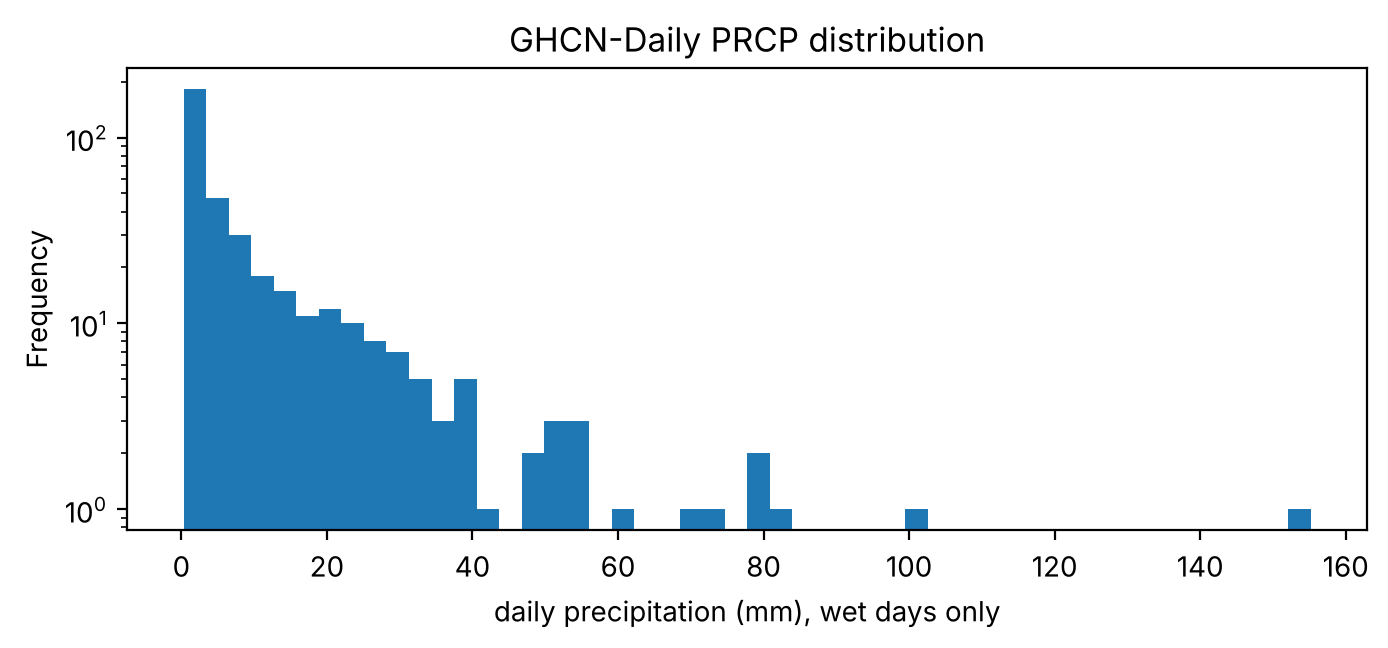

In [8]:
n = len(gh)
gaps = stations[stations["missing_days"] > 0]
if len(gaps):
    s = gaps.index[0]
    have = set(gh.loc[gh.STATION == s, "date"])
    full = pd.date_range(stations.loc[s, "first"], stations.loc[s, "last"])
    miss = [d.date().isoformat() for d in full if d not in have][:3]
    finding("ncei_ghcnd", "Missing days in the daily series (dates absent, not NULL)",
            int(gaps["missing_days"].sum()), int(stations["expected_days"].sum()),
            f"{s}: no record for {', '.join(miss)}", "Completeness check per station; never treat a missing day as 0 mm")
if "MFLAG" in gh:
    trace = gh[gh["MFLAG"] == "T"]
    if len(trace):
        ex = trace.iloc[0]
        finding("ncei_ghcnd", "Trace precipitation coded as PRCP=0 with measurement flag 'T'", len(trace), n,
                f"{ex.STATION} {ex.DATE}: PRCP={ex.PRCP}, attributes='{ex.PRCP_ATTRIBUTES}'",
                "Keep the flag in the domain table; 0 mm with T is not the same as dry")
    qf = gh[gh["QFLAG"].fillna("").str.strip() != ""]
    if len(qf):
        ex = qf.iloc[0]
        finding("ncei_ghcnd", "Values that failed a GHCN quality check (non-empty QFLAG)", len(qf), n,
                f"{ex.STATION} {ex.DATE}: PRCP={ex.PRCP}, QFLAG='{ex.QFLAG}'", "Quarantine or exclude from baselines")
    gh["OBSTIME"] = gh["OBSTIME"].fillna("").replace({"nan": "", "None": ""})
    obst = ["(empty)" if not o else o for o in gh["OBSTIME"].unique()]
    finding("ncei_ghcnd", "Daily value is a local-day total with no time zone; observation time in OBSTIME "
            f"(values seen: {', '.join(sorted(map(str, obst))[:5])})", n, n,
            f"{gh.iloc[0].STATION} {gh.iloc[0].DATE}: OBSTIME='{gh.iloc[0].OBSTIME or '(empty)'}', attributes='{gh.iloc[0].PRCP_ATTRIBUTES}'",
            "Match to events by local calendar day (+/- 1 day), not by exact UTC instant")
fig, ax = plt.subplots(figsize=(8, 3))
gh.loc[gh.prcp_mm > 0, "prcp_mm"].plot.hist(bins=50, ax=ax, log=True)
ax.set_xlabel("daily precipitation (mm), wet days only"); ax.set_title("GHCN-Daily PRCP distribution")
plt.show()

## 3. Incremental 1 - NWS station observations (latest poll)

In [9]:
rows = []
for f in sorted((LATEST / "nws_observations").glob("*.json")):
    if f.name.endswith(".meta.json"):
        continue
    for feat in read_json(f).get("features", []):
        p = feat["properties"]
        g = (feat.get("geometry") or {}).get("coordinates") or [None, None]
        r = {"station": p.get("stationId") or f.stem, "timestamp": p.get("timestamp"),
             "lon": g[0], "lat": g[1], "text": p.get("textDescription"), "raw_message": (p.get("rawMessage") or "")[:40]}
        for k in ["temperature", "precipitationLastHour", "precipitationLast3Hours", "precipitationLast6Hours",
                  "relativeHumidity", "windSpeed", "barometricPressure"]:
            v = p.get(k) or {}
            r[k] = v.get("value"); r[k + "_unit"] = v.get("unitCode"); r[k + "_qc"] = v.get("qualityControl")
        rows.append(r)
ob = pd.DataFrame(rows)
ob["ts"] = pd.to_datetime(ob["timestamp"], utc=True, errors="coerce")
print("Raw timestamp example:", ob["timestamp"].iloc[0])
display(profile(ob, "NWS observations", ["station", "timestamp"]))
print("Units seen:", {c: ob[c].dropna().unique().tolist() for c in ob if c.endswith("_unit")})
print("Time range (UTC):", ob.ts.min(), "->", ob.ts.max())
ob.groupby("station").agg(n=("ts","size"), first=("ts","min"), last=("ts","max"),
                          precip1h_null_pct=("precipitationLastHour", lambda s: round(s.isna().mean()*100,1)),
                          max_precip1h_mm=("precipitationLastHour","max"))

Raw timestamp example: 2026-11-06T02:55:00+00:00
NWS observations: 2500 records, 28 fields, duplicated ['station', 'timestamp']: 0


,station,timestamp,lon,lat,text,raw_message,temperature,temperature_unit,temperature_qc,precipitationLastHour,precipitationLastHour_unit,precipitationLastHour_qc,precipitationLast3Hours,precipitationLast3Hours_unit,precipitationLast3Hours_qc,precipitationLast6Hours,precipitationLast6Hours_unit,precipitationLast6Hours_qc,relativeHumidity,relativeHumidity_unit,relativeHumidity_qc,windSpeed,windSpeed_unit,windSpeed_qc,barometricPressure,barometricPressure_unit,barometricPressure_qc,ts
null_%,0.0,0.0,0.0,0.0,10.2,81.6,0.1,0.0,0.0,98.5,81.2,81.2,99.8,0.0,0.0,99.6,81.2,81.2,1.1,0.0,0.0,4.5,0.0,0.0,0.0,0.0,0.0,0.0


Units seen: {'temperature_unit': ['wmoUnit:degC'], 'precipitationLastHour_unit': ['wmoUnit:mm'], 'precipitationLast3Hours_unit': ['wmoUnit:mm'], 'precipitationLast6Hours_unit': ['wmoUnit:mm'], 'relativeHumidity_unit': ['wmoUnit:percent'], 'windSpeed_unit': ['wmoUnit:km_h-1'], 'barometricPressure_unit': ['wmoUnit:Pa']}
Time range (UTC): 2026-11-01 13:35:00+00:00 -> 2026-11-06 02:55:00+00:00


,n,first,last,precip1h_null_pct,max_precip1h_mm
station,,,,,
KAUS,500,2026-11-01 13:35:00+00:00,2026-11-06 02:55:00+00:00,98.6,16.5
KCRP,500,2026-11-01 20:51:00+00:00,2026-11-06 02:55:00+00:00,98.0,0.8
KDFW,500,2026-11-01 18:30:00+00:00,2026-11-06 02:55:00+00:00,99.4,0.3
KIAH,500,2026-11-01 21:35:00+00:00,2026-11-06 02:55:00+00:00,97.8,13.5
KSAT,500,2026-11-02 03:50:00+00:00,2026-11-06 02:55:00+00:00,98.8,1.3


In [10]:
n = len(ob)
p_null = ob["precipitationLastHour"].isna().sum()
if p_null:
    ex = ob[ob["precipitationLastHour"].isna()].iloc[0]
    finding("nws_observations", "precipitationLastHour is null in many observations (value: null, unitCode wmoUnit:mm)",
            int(p_null), n, f"{ex.station} {ex.timestamp}: precipitationLastHour=null, qc={ex.precipitationLastHour_qc}",
            "Only the hourly (METAR) reports carry precipitation; sum precipitationLastHour from those, never from 5-min reports")
ob = ob.sort_values(["station", "ts"])
ob["minutes_since_prev"] = ob.groupby("station")["ts"].diff().dt.total_seconds() / 60
irregular = ob[(ob["minutes_since_prev"].notna()) & ((ob["minutes_since_prev"] - 60).abs() > 5)]
if len(irregular):
    ex = irregular.iloc[0]
    top = ob["minutes_since_prev"].round().value_counts().head(3)
    mix = ", ".join(f"{int(k)} min x{v}" for k, v in top.items())
    finding("nws_observations", f"Mixed reporting intervals, not hourly (median {ob['minutes_since_prev'].median():.0f} min; most common: {mix})",
            len(irregular), n, f"{ex.station} {ex.timestamp}: {ex.minutes_since_prev:.0f} min after previous observation",
            "Aggregate to fixed hourly/daily buckets; watermark per station on timestamp, not on count")
qc_bad = ob[ob["precipitationLastHour_qc"].isin(["X", "Q", "B", "T"])]
if len(qc_bad):
    ex = qc_bad.iloc[0]
    finding("nws_observations", "Observations with failed/suspect quality-control code", len(qc_bad), n,
            f"{ex.station} {ex.timestamp}: qc={ex.precipitationLastHour_qc}", "Exclude or quarantine by QC code")

## 4. Incremental 2 - NWS alerts (active + recent, Texas, latest poll)

In [11]:
feats = {}
for f in sorted((LATEST / "nws_alerts").glob("*.json")):
    if f.name.endswith(".meta.json"):
        continue
    for feat in read_json(f).get("features", []):
        p = feat["properties"]
        feats[p["id"]] = dict(id=p["id"], event=p.get("event"), messageType=p.get("messageType"), status=p.get("status"),
                              severity=p.get("severity"), certainty=p.get("certainty"), urgency=p.get("urgency"),
                              sent=p.get("sent"), effective=p.get("effective"), onset=p.get("onset"),
                              expires=p.get("expires"), ends=p.get("ends"), areaDesc=p.get("areaDesc"),
                              n_zones=len(p.get("affectedZones") or []), n_references=len(p.get("references") or []),
                              has_geometry=feat.get("geometry") is not None, sender=p.get("senderName"),
                              source_file=f.name)
al = pd.DataFrame(feats.values())
print("Distinct alerts in latest poll:", len(al))
if len(al):
    al["sent_utc"] = pd.to_datetime(al["sent"], utc=True, errors="coerce")
    FLOOD_EVENTS = ["Flood Warning", "Flood Watch", "Flood Advisory", "Flash Flood Warning",
                    "Flash Flood Watch", "Flash Flood Statement", "Flood Statement"]
    al["is_flood"] = al["event"].isin(FLOOD_EVENTS)
    display(profile(al, "NWS alerts", ["id"]))
    print("Raw 'sent' example:", al["sent"].iloc[0])
    print("Sent range (UTC):", al.sent_utc.min(), "->", al.sent_utc.max())
    print("messageType:", al["messageType"].value_counts().to_dict())
    print("Flood-related:", int(al["is_flood"].sum()), "of", len(al))
    display(al["event"].value_counts().head(15).to_frame())

Distinct alerts in latest poll: 226
NWS alerts: 226 records, 20 fields, duplicated ['id']: 0


,id,event,messageType,status,severity,certainty,urgency,sent,effective,onset,expires,ends,areaDesc,n_zones,n_references,has_geometry,sender,source_file,sent_utc,is_flood
null_%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,16.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Raw 'sent' example: 2026-11-05T20:40:00-06:00
Sent range (UTC): 2026-10-30 03:40:00+00:00 -> 2026-11-06 02:40:00+00:00
messageType: {'Alert': 115, 'Update': 80, 'Cancel': 31}
Flood-related: 35 of 226


,count
event,
Severe Thunderstorm Warning,69
Special Weather Statement,38
Dense Fog Advisory,30
Tornado Watch,27
Flash Flood Warning,17
Flood Watch,10
Tornado Warning,8
Flood Advisory,5
Wind Advisory,5


In [12]:
if len(al):
    n = len(al)
    nogeo = al[~al["has_geometry"]]
    if len(nogeo):
        ex = nogeo.iloc[0]
        finding("nws_alerts", "Alerts without geometry (only zone/county codes in affectedZones, text in areaDesc)",
                len(nogeo), n, f"{ex.id[-36:]} {ex.event}: geometry=null, areaDesc='{str(ex.areaDesc)[:60]}'",
                "Need NWS zone/county geometries to map alerts; join on UGC/SAME codes")
    offs = al["sent"].str.extract(r"([+-]\d{2}:\d{2})$")[0].dropna().unique()
    if len(offs) and any(o != "+00:00" for o in offs):
        ex = al[~al["sent"].str.endswith("+00:00")].iloc[0]
        finding("nws_alerts", f"Timestamps in local offsets, not UTC (offsets seen: {', '.join(sorted(offs))})",
                int((~al["sent"].str.endswith("+00:00")).sum()), n, f"{ex.id[-36:]}: sent='{ex.sent}'",
                "Normalize every timestamp to UTC on ingestion")
    upd = al[al["messageType"].isin(["Update", "Cancel"])]
    if len(upd):
        ex = upd.iloc[0]
        finding("nws_alerts", "Same warning re-issued as Update/Cancel with a new id (chain via references)",
                len(upd), n, f"{ex.id[-36:]} {ex.messageType} {ex.event}: {ex.n_references} reference(s)",
                "Group alerts by reference chain; the latest message replaces earlier ones")
    other = al[~al["is_flood"]]
    if len(other):
        ex = other.iloc[0]
        finding("nws_alerts", "Feed mixes all hazards; flood-related events must be filtered by 'event'",
                len(other), n, f"{ex.id[-36:]}: event='{ex.event}'", "Filter on the event list in config/sources.yaml")

## 5. Data-quality findings (at least five, each with an example record)
Generated from the cells above, so every row comes from the real samples.

In [13]:
dq = pd.DataFrame(findings)
print(f"{len(dq)} findings")
dq.to_csv(S / "data_quality_findings.csv", index=False)
dq

11 findings


,source,problem,affected,example,impact_on_design
0,noaa_storm_events,Local timestamps without offset; zone stored a...,724/724,EVENT_ID 1256799: BEGIN_DATE_TIME='21-APR-25 1...,Convert to UTC using the offset in CZ_TIMEZONE...
1,noaa_storm_events,Damage stored as text with K/M/B suffix; empty...,724/724,EVENT_ID 1256799: DAMAGE_PROPERTY='0.00K' -> 0...,Parse to numeric USD; keep empty as NULL (unkn...
2,noaa_storm_events,No physical severity measure for floods (MAGNI...,724/724,EVENT_ID 1256799 (Flood): MAGNITUDE empty,Severity = rainfall from GHCN or impact (death...
3,ncei_ghcnd,Trace precipitation coded as PRCP=0 with measu...,232/1825,"USW00003927 2025-01-05: PRCP=0.0, attributes='...",Keep the flag in the domain table; 0 mm with T...
4,ncei_ghcnd,Daily value is a local-day total with no time ...,1825/1825,"USW00003927 2025-01-01: OBSTIME='(empty)', att...",Match to events by local calendar day (+/- 1 d...
5,nws_observations,precipitationLastHour is null in many observat...,2463/2500,KAUS 2026-11-06T02:55:00+00:00: precipitationL...,Only the hourly (METAR) reports carry precipit...
6,nws_observations,"Mixed reporting intervals, not hourly (median ...",2461/2500,KAUS 2026-11-01T13:40:00+00:00: 5 min after pr...,Aggregate to fixed hourly/daily buckets; water...
7,nws_alerts,Alerts without geometry (only zone/county code...,89/226,a938581ca63053af00abcf6f715cdb.001.1 Dense Fog...,Need NWS zone/county geometries to map alerts;...
8,nws_alerts,"Timestamps in local offsets, not UTC (offsets ...",226/226,324c74ecf2274302ec477fdf42445c.001.1: sent='20...,Normalize every timestamp to UTC on ingestion
9,nws_alerts,Same warning re-issued as Update/Cancel with a...,111/226,50cad2923b9d7c15f9df1b37f76079.001.1 Update De...,Group alerts by reference chain; the latest me...


## 6. Overlap between sources (candidate same real-world events)

Storm Events flood records with coordinates are matched to the **nearest GHCN station within 60 km** that recorded
>= 25 mm on the event's local day or the day before. Storm Events lags several months, so overlap with the NWS
incremental feeds is checked separately (alerts vs observations at the alert's counties).

In [14]:
st = stations.reset_index()[["STATION", "name", "lat", "lon"]].dropna()
ev = se[se["lat"].notna()].copy()
pairs = []
for _, e in ev.iterrows():
    d = haversine_km(e.lat, e.lon, st["lat"].values, st["lon"].values)
    i = int(np.argmin(d))
    if d[i] > 60:
        continue
    sid = st.iloc[i].STATION
    day = e.begin_local.normalize()
    win = gh[(gh.STATION == sid) & (gh.date.between(day - pd.Timedelta(days=1), day))]
    if win.empty:
        continue
    best = win.loc[win.prcp_mm.idxmax()]
    if best.prcp_mm >= 25:
        pairs.append(dict(storm_event_id=e.EVENT_ID, event_type=e.EVENT_TYPE, county=e.CZ_NAME,
                          begin_local=e.BEGIN_DATE_TIME, begin_utc=e.begin_utc, ev_lat=e.lat, ev_lon=e.lon,
                          ghcnd_station=sid, ghcnd_date=best.DATE, prcp_mm=best.prcp_mm,
                          distance_km=round(float(d[i]), 1),
                          day_offset=(best.date - day).days, damage_usd=e.damage_property_usd))
pairs = pd.DataFrame(pairs)
if len(pairs):
    pairs = pairs.sort_values(["prcp_mm", "distance_km"], ascending=[False, True])
    pairs.to_csv(S / "overlap_candidates.csv", index=False)
print(f"Candidate pairs: {len(pairs)}")
pairs.head(10)

Candidate pairs: 110


,storm_event_id,event_type,county,begin_local,begin_utc,ev_lat,ev_lon,ghcnd_station,ghcnd_date,prcp_mm,distance_km,day_offset,damage_usd
57,1272305,Flash Flood,BEXAR,12-JUN-25 03:00:00,2025-06-12 09:00:00,29.5500,-98.4800,USW00012921,2025-06-12,155.2,0.7,0,0.0
61,1272286,Flash Flood,BEXAR,12-JUN-25 02:14:00,2025-06-12 08:14:00,29.5000,-98.5000,USW00012921,2025-06-12,155.2,5.2,0,0.0
65,1272295,Flash Flood,BEXAR,12-JUN-25 02:31:00,2025-06-12 08:31:00,29.5705,-98.4114,USW00012921,2025-06-12,155.2,7.6,0,0.0
55,1272324,Flash Flood,BEXAR,12-JUN-25 03:15:00,2025-06-12 09:15:00,29.5100,-98.4100,USW00012921,2025-06-12,155.2,8.1,0,23000000.0
71,1272340,Flash Flood,BEXAR,12-JUN-25 04:11:00,2025-06-12 10:11:00,29.5100,-98.4000,USW00012921,2025-06-12,155.2,9.0,0,0.0
60,1272284,Flash Flood,BEXAR,12-JUN-25 01:46:00,2025-06-12 07:46:00,29.6400,-98.4700,USW00012921,2025-06-12,155.2,10.7,0,0.0
66,1272298,Flash Flood,BEXAR,12-JUN-25 02:50:00,2025-06-12 08:50:00,29.5600,-98.3400,USW00012921,2025-06-12,155.2,14.0,0,100000.0
58,1272208,Flash Flood,BEXAR,12-JUN-25 00:52:00,2025-06-12 06:52:00,29.5000,-98.6200,USW00012921,2025-06-12,155.2,14.1,0,0.0
59,1272279,Flash Flood,BEXAR,12-JUN-25 01:15:00,2025-06-12 07:15:00,29.4105,-98.5964,USW00012921,2025-06-12,155.2,18.4,0,0.0
64,1272290,Flash Flood,COMAL,12-JUN-25 02:26:00,2025-06-12 08:26:00,29.6350,-98.3002,USW00012921,2025-06-12,155.2,20.4,0,0.0


In [15]:
print("What differs between matched records:")
print("- identifier: Storm Events EVENT_ID vs GHCN (STATION, DATE): no shared key")
print("- time: an instant in local time (converted to UTC) vs a local-day total; day_offset shows -1/0")
print("- position: event point vs station point; distance_km above")
print("- severity: impact/damage text vs physical rainfall in mm")
if len(pairs):
    print(pairs[["distance_km", "prcp_mm", "day_offset"]].describe().round(1))

What differs between matched records:
- identifier: Storm Events EVENT_ID vs GHCN (STATION, DATE): no shared key
- time: an instant in local time (converted to UTC) vs a local-day total; day_offset shows -1/0
- position: event point vs station point; distance_km above
- severity: impact/damage text vs physical rainfall in mm
       distance_km  prcp_mm  day_offset
count        110.0    110.0       110.0
mean          29.7     73.5        -0.1
std           16.5     39.6         0.3
min            0.7     25.9        -1.0
25%           14.0     50.0         0.0
50%           29.1     61.0         0.0
75%           42.7     79.0         0.0
max           59.5    155.2         0.0


In [16]:
# Incremental overlap: flood alerts whose areaDesc names the county of an observation station
STATION_COUNTY = {"KIAH": "Harris", "KAUS": "Travis", "KSAT": "Bexar", "KDFW": "Tarrant", "KCRP": "Nueces"}
inc_pairs = []
if len(al):
    for _, a in al[al.is_flood].iterrows():
        for stn, county in STATION_COUNTY.items():
            if county in str(a.areaDesc):
                start = pd.to_datetime(a.onset or a.effective, utc=True)
                end = pd.to_datetime(a.ends or a.expires, utc=True)
                o = ob[(ob.station == stn) & ob.ts.between(start - pd.Timedelta(hours=6), end)]
                inc_pairs.append(dict(alert_id=a.id[-36:], event=a.event, county=county, station=stn,
                                      alert_start=start, alert_end=end, n_obs=len(o),
                                      precip_sum_mm=o.precipitationLastHour.sum(min_count=1)))
inc_pairs = pd.DataFrame(inc_pairs)
print(f"Alert-station candidate pairs: {len(inc_pairs)} (zero is normal when no flood alerts are active)")
inc_pairs.head(10)

Alert-station candidate pairs: 2 (zero is normal when no flood alerts are active)


,alert_id,event,county,station,alert_start,alert_end,n_obs,precip_sum_mm
0,324c74ecf2274302ec477fdf42445c.001.1,Flood Advisory,Nueces,KCRP,2026-11-06 02:40:00+00:00,2026-11-06 04:45:00+00:00,38,1.6
1,eeca440e10a5584bbbc9d926e485c8.001.1,Flood Advisory,Nueces,KCRP,2026-10-30 14:25:00+00:00,2026-10-30 17:30:00+00:00,0,NaN


## 7. Volume estimate and incremental behavior

In [17]:
vol = pd.read_csv(S / "storm_events" / "volume_estimate.csv")
tx_rows_year = len(se)
print(f"Storm Events details files {vol.year.min()}-{vol.year.max()}: {len(vol)} files, "
      f"{vol.bytes_gz.sum()/1e6:.1f} MB compressed")
print(f"Texas flood-related rows in sample year: {tx_rows_year} -> about {tx_rows_year*len(vol):,} rows for the window")
print(f"GHCN-Daily: {len(stations)} stations x 365 days x {len(vol)} years = about {len(stations)*365*len(vol):,} rows")
cmp = S / "polls" / "poll_comparison.md"
print("\n" + (cmp.read_text(encoding="utf-8") if cmp.exists() else "Run scripts/compare_polls.py after the second poll."))

Storm Events details files 2010-2026: 17 files, 194.9 MB compressed
Texas flood-related rows in sample year: 724 -> about 12,308 rows for the window
GHCN-Daily: 5 stations x 365 days x 17 years = about 31,025 rows

# Incremental poll comparison

- Poll 1: `poll_20261106T022015Z`
- Poll 2: `poll_20261106T032630Z`

## NWS alerts (active + recent, Texas)
- Poll 1: 226 distinct alert ids; poll 2: 226
- New ids in poll 2: 1; ids no longer returned: 1
- Same id, different content: 0
- New alerts that reference earlier alerts (Update/Cancel chain): 0
- messageType in poll 2: Alert=115, Cancel=31, Update=80


## NWS station observations
| station | obs poll 1 | obs poll 2 | newest ts poll 1 | newest ts poll 2 | new ts | overlapping ts with changed values |
|---|---|---|---|---|---|---|
| KAUS | 500 | 500 | 2026-11-06T01:15:00+00:00 | 2026-11-06T02:55:00+00:00 | 7 | 0 |
| KCRP | 500 | 500 | 2026-11-06T01:24:00+00:00 | 2026-11-06T02:55:00+00:00 | 8 | 0 |
| KDFW | 500 | 500 | 2026-11-06T01:15:00+

## 8. Summary
- Findings table: `workshop_1/samples/data_quality_findings.csv`
- Overlap candidates: `workshop_1/samples/overlap_candidates.csv`
- Poll comparison: `workshop_1/samples/polls/poll_comparison.md`

Copy the relevant tables and snippets into the report (sections 4-5).